In [1]:
# =====================================
# Cell 1: Env & GPU setup
# =====================================
import os
os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"

import gc, pathlib, re, math, numpy as np
from google.colab import drive

import tensorflow as tf
from tensorflow.keras import mixed_precision

# Mount Drive
drive.mount('/content/drive')

# Mixed precision for speed (A100/T4)
mixed_precision.set_global_policy('float32')

# Allow dynamic GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except:
        pass

# Global seed
SEED_BASE = 42
np.random.seed(SEED_BASE)
tf.random.set_seed(SEED_BASE)

print("Drive mounted, mixed precision ON, GPU growth set, seed =", SEED_BASE)


Mounted at /content/drive
Drive mounted, mixed precision ON, GPU growth set, seed = 42


In [2]:
from pathlib import Path

dataset_path = Path("/content/drive/MyDrive/Merge 2/Concentrations")

print("Dataset folder exists:", dataset_path.exists())
print("\nFolders and image counts:\n")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        images = [
            file for file in folder.rglob("*")
            if file.suffix.lower() in image_extensions
        ]

        print(f"{folder.name}: {len(images)} images")

Dataset folder exists: True

Folders and image counts:

0.02ng: 30 images
0.04ng: 63 images
0.06ng: 77 images
0.08ng: 68 images
0.1ng: 60 images


In [3]:
# =====================================
# Cell 2: Config & Paths (Regression on MERGED brands)
# =====================================
DATA_DIR = "/content/drive/MyDrive/Merge 2/Concentrations"

IMG_SIZE        = (224, 224)
BATCH_SIZE      = 8
K_FOLDS         = 5
EPOCHS_LENET    = 17
LR_HEAD         = 1e-4
STDS_TO_RUN     = [0, 1, 5, 50]  # same noise stress-test

OUT_DIR = "/content/drive/MyDrive/colab_runs/MERGED_LeNet5_REGRESSION_224"
os.makedirs(OUT_DIR, exist_ok=True)

print("DATA_DIR:", DATA_DIR)
print("OUT_DIR:", OUT_DIR)


DATA_DIR: /content/drive/MyDrive/Merge 2/Concentrations
OUT_DIR: /content/drive/MyDrive/colab_runs/MERGED_LeNet5_REGRESSION_224


In [4]:
# =====================================
# Cell 3: List files + numeric concentration targets
# =====================================
import os, pathlib, re, numpy as np

def parse_conc_from_folder(name: str):
    s = name.lower().strip()
    if "control" in s:
        return 0.0  # treat Control as 0 ng
    m = re.search(r'([0-9]*\.?[0-9]+)', s)
    if not m:
        return None
    return float(m.group(1))

def list_files_and_values(data_dir: str):
    data_dir = pathlib.Path(data_dir)
    filepaths, y_vals = [], []
    for cname in os.listdir(data_dir):
        cdir = data_dir / cname
        if not cdir.is_dir():
            continue
        conc = parse_conc_from_folder(cname)
        if conc is None:
            continue
        for p in cdir.iterdir():
            if p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".tif",".tiff"}:
                filepaths.append(str(p))
                y_vals.append(conc)
    if not filepaths:
        raise RuntimeError(f"No images found under {data_dir}")
    # sort together by numeric conc (optional, just for readability)
    order = np.argsort(y_vals)
    return np.array(filepaths)[order], np.array(y_vals, dtype=np.float32)[order]

all_paths, all_targets_ng = list_files_and_values(DATA_DIR)
print(f"Total images: {len(all_paths)} | Min-Max conc (ng): {all_targets_ng.min()} - {all_targets_ng.max()}")

# ---- target transform: y = log10(1 + conc) for stability & zero-safe
import numpy as np
LOG_BASE = 10.0
def to_log10p(x):     # x in ng
    return np.log1p(x) / np.log(LOG_BASE)
def from_log10p(y):   # back to ng
    return np.expm1(y * np.log(LOG_BASE))

all_targets_y = to_log10p(all_targets_ng)


Total images: 298 | Min-Max conc (ng): 0.019999999552965164 - 0.10000000149011612


In [5]:
# Check how many usable images we have for each concentration

from collections import Counter

counts = Counter(all_targets_ng)

print("Images per concentration:")
for concentration in sorted(counts):
    print(f"{concentration:.2f} ng: {counts[concentration]} images")

Images per concentration:
0.02 ng: 30 images
0.04 ng: 63 images
0.06 ng: 77 images
0.08 ng: 68 images
0.10 ng: 60 images


0.02 ng: 30 images found
0.04 ng: 63 images found
0.06 ng: 77 images found
0.08 ng: 68 images found
0.10 ng: 60 images found


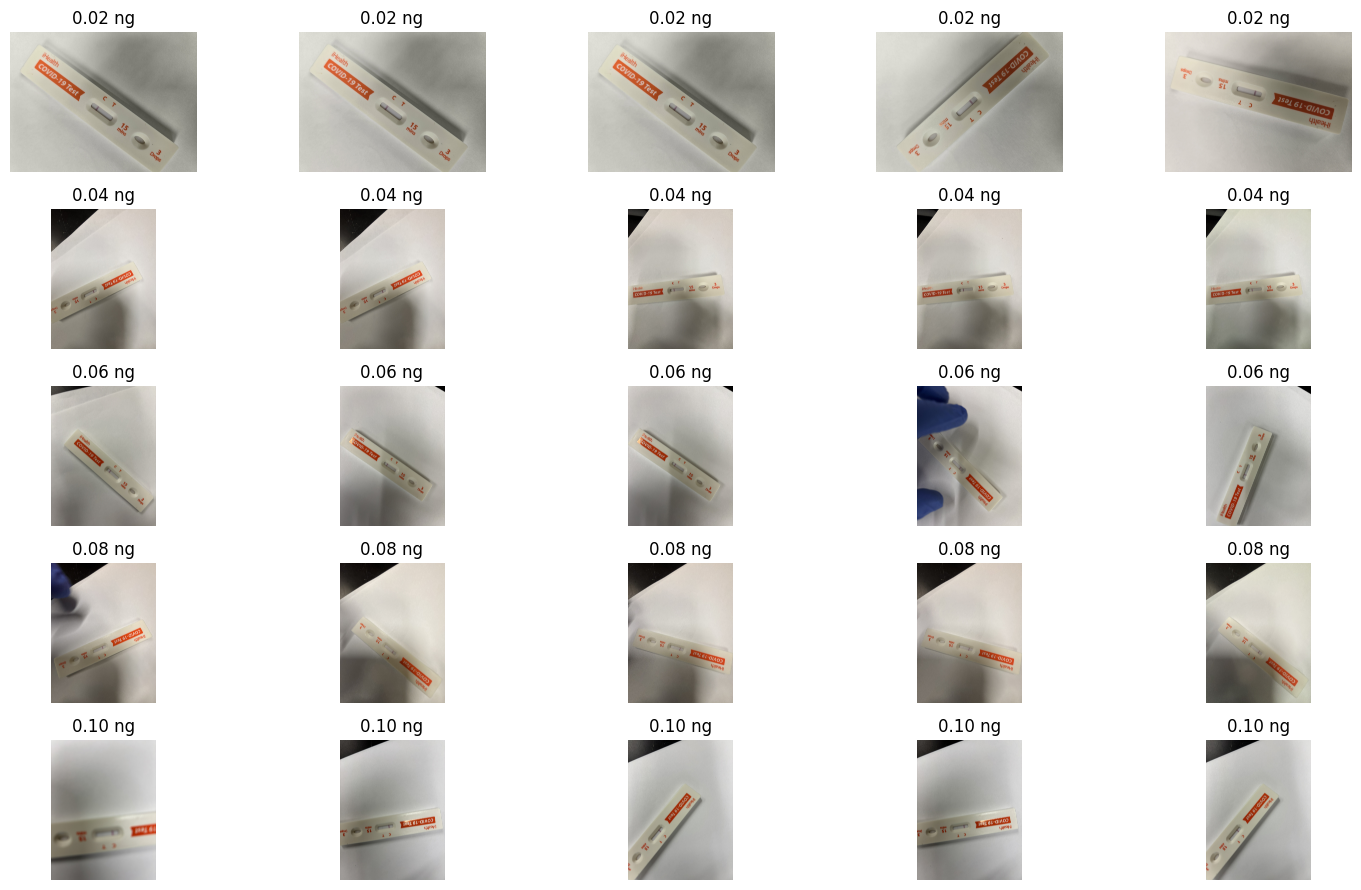

In [17]:
# =====================================
# Quick Image Check
# =====================================

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

concentrations_to_check = [0.02, 0.04, 0.06, 0.08, 0.10]

fig, axes = plt.subplots(
    5, 5,
    figsize=(15, 9)
)

for row, concentration in enumerate(concentrations_to_check):

    # Find images belonging to this concentration
    indices = np.where(
        np.isclose(all_targets_ng, concentration)
    )[0]

    print(f"{concentration:.2f} ng: {len(indices)} images found")

    # Show first 5
    for col, idx in enumerate(indices[:5]):

        img = tf.io.read_file(all_paths[idx])
        img = tf.image.decode_image(
            img,
            channels=3,
            expand_animations=False
        )

        axes[row, col].imshow(img.numpy())
        axes[row, col].set_title(
            f"{concentration:.2f} ng"
        )
        axes[row, col].axis("off")


plt.tight_layout()
plt.show()

In [7]:
# =====================================
# Cell 4: tf.data pipeline (regression labels as float32)
# =====================================
import tensorflow as tf
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize_rescale(path, y):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE, method=tf.image.ResizeMethod.BILINEAR)
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.cast(y, tf.float32)

def light_aug(img, y):
    img = tf.image.random_brightness(img, max_delta=0.1)
    img = tf.image.random_contrast(img, lower=0.9, upper=1.1)
    return img, y

def add_gaussian_noise(std_on_255: int):
    if std_on_255 == 0:
        return lambda img, y: (img, y)
    std = tf.constant(std_on_255/255.0, tf.float32)
    def f(img, y):
        noise = tf.random.normal(tf.shape(img), mean=0.0, stddev=std, dtype=tf.float32)
        return tf.clip_by_value(img + noise, 0.0, 1.0), y
    return f

def build_ds(paths, labels, batch, training, std_on_255):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED_BASE, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize_rescale, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(light_aug, num_parallel_calls=AUTOTUNE)
    ds = ds.map(add_gaussian_noise(std_on_255), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x,y: (tf.cast(x, tf.float16), y), num_parallel_calls=AUTOTUNE)  # fp16 images, fp32 labels
    ds = ds.batch(batch).prefetch(AUTOTUNE)
    return ds

print("tf.data pipeline ready for regression.")


tf.data pipeline ready for regression.


In [8]:
!pip install -q tensorflow-probability

In [9]:
import tensorflow_probability as tfp

tfpl = tfp.layers

print("TensorFlow Probability loaded!")
print("DenseFlipout is available:", hasattr(tfpl, "DenseFlipout"))

TensorFlow Probability loaded!
DenseFlipout is available: True


In [10]:
# =====================================
# Cell 5: Bayesian LeNet-5 Regression Model
# =====================================

import tensorflow as tf
import tf_keras
import tensorflow_probability as tfp

tfpl = tfp.layers

from tf_keras import Model
from tf_keras.layers import Input, Conv2D, AveragePooling2D, Flatten
from tf_keras.optimizers import Adam
from tf_keras.callbacks import EarlyStopping, ReduceLROnPlateau


def r2_metric(y_true, y_pred):
    y_true_mean = tf.reduce_mean(y_true)

    ss_res = tf.reduce_sum(
        tf.square(y_true - y_pred)
    )

    ss_tot = tf.reduce_sum(
        tf.square(y_true - y_true_mean)
    ) + 1e-12

    return 1.0 - ss_res / ss_tot


def rmse_metric(y_true, y_pred):
    return tf.sqrt(
        tf.reduce_mean(
            tf.square(y_true - y_pred)
        )
    )


def build_lenet5_regressor(input_shape):

    inp = Input(shape=input_shape)

    # ----- Original LeNet-5 convolution layers -----

    x = Conv2D(
        6,
        (5, 5),
        activation='relu'
    )(inp)

    x = AveragePooling2D(
        pool_size=(2, 2)
    )(x)

    x = Conv2D(
        16,
        (5, 5),
        activation='relu'
    )(x)

    x = AveragePooling2D(
        pool_size=(2, 2)
    )(x)

    x = Flatten()(x)

    # ----- Bayesian Dense Layers -----

    x = tfpl.DenseFlipout(
        120,
        activation='relu'
    )(x)

    x = tfpl.DenseFlipout(
        84,
        activation='relu'
    )(x)

    # Bayesian regression output
    out = tfpl.DenseFlipout(
        1
    )(x)

    model = Model(inp, out)

    model.compile(
        optimizer=Adam(
            learning_rate=LR_HEAD
        ),
        loss=tf_keras.losses.Huber(
            delta=1.0
        ),
        metrics=[
            tf_keras.metrics.MeanAbsoluteError(
                name="mae"
            ),
            rmse_metric,
            r2_metric
        ]
    )

    return model


cbs_head = [
    EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
]


print("Bayesian LeNet-5 regressor compiled.")

Bayesian LeNet-5 regressor compiled.


In [11]:
# Install HEIC support
!pip -q install pillow-heif

from PIL import Image
from pillow_heif import register_heif_opener
import os
from pathlib import Path

# Enable HEIC/HEIF reading
register_heif_opener()

# The same folder used by the notebook
DATA_DIR = "/content/drive/MyDrive/Merge 2/Concentrations"

# Concentration folders we want to process
folders = ["0.04ng", "0.06ng", "0.08ng", "0.1ng"]

converted = 0
skipped = 0
errors = 0

for folder in folders:
    folder_path = Path(DATA_DIR) / folder

    print(f"\nProcessing {folder}...")

    for heic_file in folder_path.iterdir():

        # Only convert HEIC files
        if heic_file.suffix.lower() not in [".heic", ".heif"]:
            continue

        # Create the JPG filename
        jpg_file = heic_file.with_suffix(".jpg")

        # Don't convert again if JPG already exists
        if jpg_file.exists():
            skipped += 1
            continue

        try:
            # Open HEIC
            img = Image.open(heic_file)

            # Convert to RGB
            img = img.convert("RGB")

            # Save as JPG
            img.save(jpg_file, "JPEG", quality=95)

            converted += 1

        except Exception as e:
            errors += 1
            print(f"  ERROR: {heic_file.name}")
            print(f"  {e}")

    print(f"Finished {folder}")

print("\n==============================")
print("HEIC CONVERSION COMPLETE")
print("==============================")
print(f"Converted: {converted}")
print(f"Skipped:   {skipped}")
print(f"Errors:    {errors}")


Processing 0.04ng...
  ERROR: IMG_1487.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1487.HEIC'
  ERROR: IMG_1506.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1506.HEIC'
  ERROR: IMG_1511.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1511.HEIC'
  ERROR: IMG_1519.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1519.HEIC'
  ERROR: IMG_1527.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1527.HEIC'
  ERROR: IMG_1535.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1535.HEIC'
  ERROR: IMG_1543.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1543.HEIC'
  ERROR: IMG_1551.HEIC
  cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1551.HEIC'
Finished 0

In [12]:
# Check the actual file types of the HEIC files

from pathlib import Path

folders = ["0.04ng", "0.06ng", "0.08ng", "0.1ng"]

for folder in folders:
    folder_path = Path(DATA_DIR) / folder

    print(f"\n===== {folder} =====")

    heic_files = list(folder_path.glob("*.HEIC")) + list(folder_path.glob("*.heic"))

    print("HEIC files found:", len(heic_files))

    if heic_files:
        for f in heic_files[:5]:
            with open(f, "rb") as file:
                header = file.read(20)

            print(f"{f.name}: {header}")


===== 0.04ng =====
HEIC files found: 71
IMG_1485.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1484.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1481.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1486.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1482.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'

===== 0.06ng =====
HEIC files found: 87
IMG_1395.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1400.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1398.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1399.HEIC: b'\x00\x00\x00\x14ftypqt  \x00\x00\x00\x00qt  '
IMG_1396.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'

===== 0.08ng =====
HEIC files found: 89
IMG_1236.HEIC: b'\x00\x00\x00,ftypheic\x00\x00\x00\x00mif1'
IMG_1237.HEIC: b'\x00\x00\x00\x14ftypqt  \x00\x00\x00\x00qt  '
IMG_1238.HEIC: b'\x00\x00\x00\x14ftypqt  \x00\x00\x00\x00qt  '
IMG_1240.HEIC: b'\x00\x00\x00\x14ftypqt  \x00\x00\x00\x00qt  '
IMG_1239.HEIC: b'\x00\x00

In [13]:
# Test HEIC conversion on a few files

from PIL import Image
from pillow_heif import register_heif_opener
from pathlib import Path

register_heif_opener()

test_folder = Path(DATA_DIR) / "0.04ng"
heic_files = list(test_folder.glob("*.HEIC")) + list(test_folder.glob("*.heic"))

successful = 0
failed = 0

for heic_file in heic_files[:10]:
    try:
        img = Image.open(heic_file)
        print(f"SUCCESS: {heic_file.name} -> {img.format}, {img.size}")
        successful += 1
    except Exception as e:
        print(f"FAILED:  {heic_file.name} -> {e}")
        failed += 1

print("\nTest complete")
print("Successful:", successful)
print("Failed:", failed)

SUCCESS: IMG_1485.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1484.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1481.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1486.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1482.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1483.HEIC -> HEIF, (3024, 4032)
FAILED:  IMG_1487.HEIC -> cannot identify image file '/content/drive/MyDrive/Merge 2/Concentrations/0.04ng/IMG_1487.HEIC'
SUCCESS: IMG_1490.HEIC -> HEIF, (3024, 4032)
SUCCESS: IMG_1488.HEIC -> HEIF, (4284, 5712)
SUCCESS: IMG_1489.HEIC -> HEIF, (4284, 5712)

Test complete
Successful: 9
Failed: 1


In [14]:
# Quick BNN model test

test_model = build_lenet5_regressor(IMG_SIZE + (3,))

test_model.summary()

print("✅ BNN model successfully created!")

/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scale = add_variable_fn(
/usr/local/lib/python3.13/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 conv2d (Conv2D)             (None, 220, 220, 6)       456       
                                                                 
 average_pooling2d (Average  (None, 110, 110, 6)       0         
 Pooling2D)                                                      
                                                                 
 conv2d_1 (Conv2D)           (None, 106, 106, 16)      2416      
                                                                 
 average_pooling2d_1 (Avera  (None, 53, 53, 16)        0         
 gePooling2D)                                                    
                                                                 
 flatten (Flatten)           (None, 44944)             0     

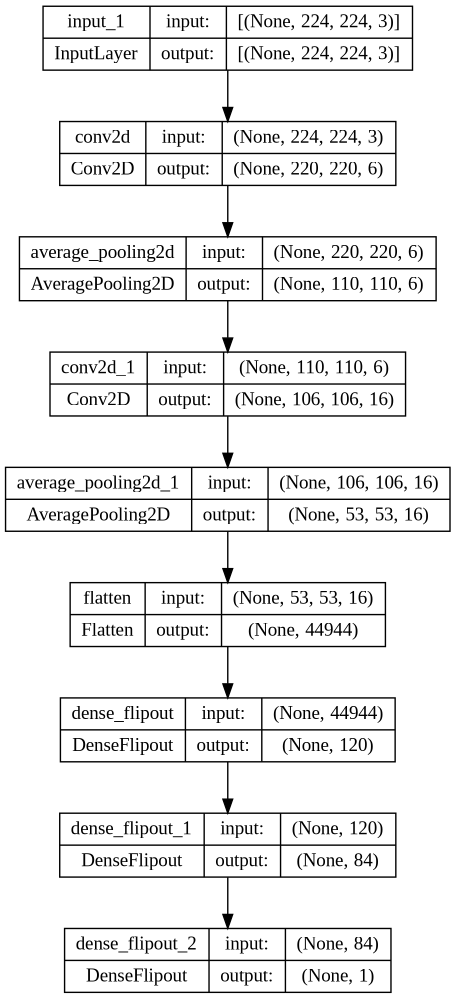

✅ BNN architecture diagram successfully created!


In [15]:
# =====================================
# BNN Model Architecture Diagram
# =====================================

from tf_keras.utils import plot_model
from IPython.display import Image, display

plot_model(
    test_model,
    show_shapes=True,
    show_layer_names=True,
    dpi=100,
    to_file="BNN_Model_Architecture.png"
)

display(Image(filename="BNN_Model_Architecture.png"))

print("✅ BNN architecture diagram successfully created!")

In [23]:
# =====================================
# Step 5: Small BNN training test
# =====================================

# Use a small portion of the training data
test_paths = tr_paths_full[:20]
test_y = tr_y_full[:20]

# Build a small training dataset
test_ds = build_ds(
    test_paths,
    test_y,
    BATCH_SIZE,
    training=True,
    std_on_255=0
)

# Build validation dataset
val_paths = tr_paths_full[20:30]
val_y = tr_y_full[20:30]

val_ds = build_ds(
    val_paths,
    val_y,
    BATCH_SIZE,
    training=False,
    std_on_255=0
)

# Create a fresh Bayesian model
test_bnn = build_lenet5_regressor(IMG_SIZE + (3,))

# Train for only 2 epochs
history = test_bnn.fit(
    test_ds,
    validation_data=val_ds,
    epochs=2,
    verbose=1
)

print("✅ BNN training test completed!")

/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/usr/local/lib/python3.13/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scale = add_variable_fn(


Epoch 1/2
3/3 [==============================] - 12s 3s/step - loss: 13674306.0000 - mae: 0.6073 - rmse_metric: 0.6103 - r2_metric: -4773.5542 - val_loss: 13673054.0000 - val_mae: 0.6101 - val_rmse_metric: 0.6154 - val_r2_metric: -13118.2236
Epoch 2/2
3/3 [==============================] - 6s 2s/step - loss: 13672600.0000 - mae: 0.6405 - rmse_metric: 0.6511 - r2_metric: -5264.0117 - val_loss: 13671349.0000 - val_mae: 0.5424 - val_rmse_metric: 0.5485 - val_r2_metric: -10335.8369
✅ BNN training test completed!


In [18]:
# =====================================
# Step 6A: BNN stochastic predictions
# =====================================

import numpy as np

def bnn_predict_with_uncertainty(model, dataset, n_samples=30):

    predictions = []

    # Get only the images from the dataset
    images = []

    for x_batch, y_batch in dataset:
        images.append(x_batch)

    images = tf.concat(images, axis=0)

    # Make multiple stochastic predictions
    for _ in range(n_samples):

        pred = model(
            images,
            training=True
        )

        predictions.append(
            pred.numpy().reshape(-1)
        )

    all_predictions = np.stack(
        predictions,
        axis=0
    )

    mean_prediction = np.mean(
        all_predictions,
        axis=0
    )

    uncertainty = np.std(
        all_predictions,
        axis=0
    )

    return (
        mean_prediction,
        uncertainty,
        all_predictions
    )


print("✅ BNN uncertainty function ready!")

✅ BNN uncertainty function ready!


In [24]:
# =====================================
# Step 6B: Test BNN uncertainty
# =====================================

mean_pred, uncertainty, all_preds = bnn_predict_with_uncertainty(
    test_bnn,
    val_ds,
    n_samples=30
)

print("Number of predictions:", len(mean_pred))

print("First 10 mean predictions:")
print(mean_pred[:10])

print("\nFirst 10 uncertainty values:")
print(uncertainty[:10])

print("\nAverage uncertainty:",
      np.mean(uncertainty))

print("Maximum uncertainty:",
      np.max(uncertainty))

print("Minimum uncertainty:",
      np.min(uncertainty))

Number of predictions: 10
First 10 mean predictions:
[0.5501304  0.5611382  0.57822794 0.49547538 0.5587111  0.64132667
 0.6022884  0.57551706 0.50350547 0.51422787]

First 10 uncertainty values:
[0.11321006 0.10150892 0.11160727 0.11094349 0.10190448 0.12256806
 0.11248    0.11180931 0.12447283 0.08052666]

Average uncertainty: 0.10910312
Maximum uncertainty: 0.124472834
Minimum uncertainty: 0.08052666


In [21]:
# =====================================
# Cell 6: Fixed 80/20 split with stratification by binned targets
# =====================================
from sklearn.model_selection import train_test_split
import numpy as np

# bin the *numeric* targets for stratified split
n_bins = min(15, max(5, int(np.sqrt(len(all_targets_y)))))  # heuristic
bins = np.linspace(all_targets_y.min(), all_targets_y.max()+1e-9, n_bins+1)
y_bins = np.digitize(all_targets_y, bins) - 1

idx_all = np.arange(len(all_targets_y))
train_idx, test_idx = train_test_split(
    idx_all, test_size=0.20, stratify=y_bins, random_state=SEED_BASE)

tr_paths_full, tr_y_full = all_paths[train_idx], all_targets_y[train_idx]
te_paths, te_y = all_paths[test_idx], all_targets_y[test_idx]

print(f"Train (80%): {len(tr_paths_full)} | Test (20%): {len(te_paths)}")

def build_test_ds(std):
    return build_ds(te_paths, te_y, BATCH_SIZE, training=False, std_on_255=std)


Train (80%): 238 | Test (20%): 60


In [25]:
# Training settings for the BNN
EPOCHS_HEAD = 5
BATCH_SIZE = 16

print("EPOCHS_HEAD =", EPOCHS_HEAD)
print("BATCH_SIZE =", BATCH_SIZE)

EPOCHS_HEAD = 5
BATCH_SIZE = 16


In [ ]:
# =====================================
# Cell 7: FULL BNN 5-Fold Cross-Validation
# Optimized for the expanded 298-image dataset
# =====================================

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import tf_keras
from sklearn.model_selection import StratifiedKFold

# =====================================
# FULL EXPERIMENT SETTINGS
# =====================================

NOISE_STDS = [0, 1, 5, 50]

# Number of stochastic BNN predictions
N_BNN_SAMPLES = 15

# Store results
all_results = []

print("=====================================")
print("FULL BNN EXPERIMENT")
print("=====================================")
print(f"Total images: {len(all_paths)}")
print(f"Train images: {len(tr_paths_full)}")
print(f"Test images: {len(te_paths)}")
print(f"Noise levels: {NOISE_STDS}")
print(f"Epochs: {EPOCHS_HEAD}")
print(f"Batch size: {BATCH_SIZE}")
print(f"BNN samples: {N_BNN_SAMPLES}")
print("=====================================")


# =====================================
# Create concentration bins
# =====================================

n_bins = min(
    5,
    max(2, int(np.sqrt(len(tr_y_full))))
)

bins = np.linspace(
    tr_y_full.min(),
    tr_y_full.max() + 1e-9,
    n_bins + 1
)

y_bins = np.digitize(
    tr_y_full,
    bins
) - 1


# =====================================
# 5-fold cross-validation
# =====================================

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# =====================================
# Main experiment
# =====================================

for std in NOISE_STDS:

    print("\n=====================================")
    print(f"NOISE STD = {std}")
    print("=====================================")

    fold_results = []

    # ---------------------------------
    # Build fixed test dataset ONCE
    # for this noise level
    # ---------------------------------

    te_ds = build_test_ds(std)

    test_images = []

    for x_batch, y_batch in te_ds:
        test_images.append(x_batch)

    test_images = tf.concat(
        test_images,
        axis=0
    )

    print(
        f"Test images loaded for STD={std}: "
        f"{test_images.shape[0]}"
    )


    # =================================
    # Five folds
    # =================================

    for fold, (tr_idx, va_idx) in enumerate(
        skf.split(tr_paths_full, y_bins),
        start=1
    ):

        print("\n-------------------------------------")
        print(f"STD={std} | Fold {fold}/5")
        print("-------------------------------------")


        # ---------------------------------
        # Split training data
        # ---------------------------------

        fold_tr_paths = tr_paths_full[tr_idx]
        fold_tr_y = tr_y_full[tr_idx]

        fold_va_paths = tr_paths_full[va_idx]
        fold_va_y = tr_y_full[va_idx]


        # ---------------------------------
        # Build datasets
        # ---------------------------------

        ds_tr = build_ds(
            fold_tr_paths,
            fold_tr_y,
            BATCH_SIZE,
            training=True,
            std_on_255=std
        )

        ds_va = build_ds(
            fold_va_paths,
            fold_va_y,
            BATCH_SIZE,
            training=False,
            std_on_255=std
        )


        # ---------------------------------
        # Create fresh Bayesian model
        # ---------------------------------

        model = build_lenet5_regressor(
            IMG_SIZE + (3,)
        )


        # ---------------------------------
        # Train model
        # ---------------------------------

        model.fit(
            ds_tr,
            validation_data=ds_va,
            epochs=EPOCHS_HEAD,
            callbacks=cbs_head,
            verbose=1
        )


        # =================================
        # BNN stochastic predictions
        # =================================

        stochastic_predictions = []

        for sample in range(N_BNN_SAMPLES):

            pred = model(
                test_images,
                training=True
            )

            stochastic_predictions.append(
                pred.numpy().reshape(-1)
            )

        stochastic_predictions = np.stack(
            stochastic_predictions,
            axis=0
        )


        # ---------------------------------
        # Mean prediction
        # ---------------------------------

        mean_pred_y = np.mean(
            stochastic_predictions,
            axis=0
        )


        # ---------------------------------
        # BNN uncertainty
        # ---------------------------------

        uncertainty_y = np.std(
            stochastic_predictions,
            axis=0
        )


        # ---------------------------------
        # Convert back to ng
        # ---------------------------------

        mean_pred_ng = from_log10p(
            mean_pred_y
        )

        true_ng = from_log10p(
            te_y
        )


        # ---------------------------------
        # Calculate MAE
        # ---------------------------------

        mae = np.mean(
            np.abs(
                mean_pred_ng - true_ng
            )
        )


        # ---------------------------------
        # Calculate RMSE
        # ---------------------------------

        rmse = np.sqrt(
            np.mean(
                (mean_pred_ng - true_ng) ** 2
            )
        )


        # ---------------------------------
        # Average uncertainty
        # ---------------------------------

        avg_uncertainty = np.mean(
            uncertainty_y
        )


        # =================================
        # Save predictions
        # =================================

        prediction_df = pd.DataFrame({
            "y_true_ng": true_ng,
            "y_pred_ng": mean_pred_ng,
            "uncertainty_y": uncertainty_y
        })

        prediction_path = os.path.join(
            OUT_DIR,
            f"predictions_std_{std}_fold_{fold}.csv"
        )

        prediction_df.to_csv(
            prediction_path,
            index=False
        )


        # =================================
        # Store results
        # =================================

        fold_results.append({
            "fold": fold,
            "noise_std": std,
            "mae_ng": mae,
            "rmse_ng": rmse,
            "mean_uncertainty": avg_uncertainty
        })


        print(
            f"Fold {fold} complete | "
            f"MAE={mae:.4f} ng | "
            f"RMSE={rmse:.4f} ng | "
            f"Mean uncertainty={avg_uncertainty:.4f}"
        )


        # =================================
        # Clean up model memory
        # =================================

        del model
        del ds_tr
        del ds_va
        del stochastic_predictions

        tf_keras.backend.clear_session()
        gc.collect()


    # ---------------------------------
    # Add fold results
    # ---------------------------------

    all_results.extend(
        fold_results
    )


# =====================================
# Create final results DataFrame
# =====================================

results_df = pd.DataFrame(
    all_results
)


# =====================================
# Save full results
# =====================================

results_path = os.path.join(
    OUT_DIR,
    "BNN_full_results_298_images.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


# =====================================
# Final output
# =====================================

print("\n=====================================")
print("FULL BNN EXPERIMENT COMPLETE!")
print("=====================================")

print(results_df)

print("\nResults saved to:")
print(results_path)

FULL BNN EXPERIMENT
Total images: 298
Train images: 238
Test images: 60
Noise levels: [0, 1, 5, 50]
Epochs: 5
Batch size: 16
BNN samples: 15

NOISE STD = 0
Test images loaded for STD=0: 60

-------------------------------------
STD=0 | Fold 1/5
-------------------------------------


/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/usr/local/lib/python3.13/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scale = add_variable_fn(


Epoch 1/5
12/12 [==============================] - 49s 4s/step - loss: 13671669.0000 - mae: 2.5685 - rmse_metric: 3.1662 - r2_metric: -109672.1641 - val_loss: 13667941.0000 - val_mae: 1.3545 - val_rmse_metric: 1.5874 - val_r2_metric: -25756.1348 - lr: 1.0000e-04
Epoch 2/5
12/12 [==============================] - 45s 4s/step - loss: 13664853.0000 - mae: 1.4387 - rmse_metric: 1.7781 - r2_metric: -33870.7617 - val_loss: 13661133.0000 - val_mae: 1.2985 - val_rmse_metric: 1.6667 - val_r2_metric: -27680.0879 - lr: 1.0000e-04
Epoch 3/5
12/12 [==============================] - 44s 4s/step - loss: 13658049.0000 - mae: 1.1196 - rmse_metric: 1.3776 - r2_metric: -19563.6738 - val_loss: 13654333.0000 - val_mae: 1.1025 - val_rmse_metric: 1.4457 - val_r2_metric: -21391.5254 - lr: 1.0000e-04
Epoch 4/5
12/12 [==============================] - 44s 4s/step - loss: 13651253.0000 - mae: 0.8739 - rmse_metric: 1.0662 - r2_metric: -12457.7607 - val_loss: 13647541.0000 - val_mae: 0.8584 - val_rmse_metric: 1.07

/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:99: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  loc = add_variable_fn(
/usr/local/lib/python3.13/dist-packages/tf_keras/src/initializers/initializers.py:121: UserWarning: The initializer RandomNormal is unseeded and being called multiple times, which will return identical values each time (even if the initializer is unseeded). Please update your code to provide a seed to the initializer, or avoid using the same initializer instance more than once.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow_probability/python/layers/util.py:109: UserWarning: `layer.add_variable` is deprecated and will be removed in a future version. Please use the `layer.add_weight()` method instead.
  untransformed_scale = add_variable_fn(


Epoch 1/5
12/12 [==============================] - 45s 3s/step - loss: 13671669.0000 - mae: 2.4401 - rmse_metric: 2.8308 - r2_metric: -89712.8438 - val_loss: 13667941.0000 - val_mae: 1.0102 - val_rmse_metric: 1.2607 - val_r2_metric: -15847.2236 - lr: 1.0000e-04
Epoch 2/5
12/12 [==============================] - 47s 4s/step - loss: 13664853.0000 - mae: 0.7903 - rmse_metric: 0.9510 - r2_metric: -9995.5029 - val_loss: 13661131.0000 - val_mae: 0.7080 - val_rmse_metric: 0.9069 - val_r2_metric: -8673.9258 - lr: 1.0000e-04
Epoch 3/5
12/12 [==============================] - 43s 3s/step - loss: 13658045.0000 - mae: 0.5286 - rmse_metric: 0.6495 - r2_metric: -4349.9399 - val_loss: 13654331.0000 - val_mae: 0.6075 - val_rmse_metric: 0.7495 - val_r2_metric: -5597.5938 - lr: 1.0000e-04
Epoch 4/5
12/12 [==============================] - ETA: 0s - loss: 13651251.0000 - mae: 0.4805 - rmse_metric: 0.5770 - r2_metric: -3508.0413

In [ ]:
# =====================================
# Plot NEW BNN Predictions
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

prediction_files = [
    f for f in os.listdir(OUT_DIR)
    if f.startswith("predictions_std_0_fold_")
    and f.endswith(".csv")
]

print("Prediction files found:", len(prediction_files))

# Use the first saved fold for the quick test
prediction_file = os.path.join(
    OUT_DIR,
    sorted(prediction_files)[0]
)

df_plot = pd.read_csv(prediction_file)

y_true = df_plot["y_true_ng"].to_numpy()
y_pred = df_plot["y_pred_ng"].to_numpy()

# Only use positive values for log-log plot
mask = (y_true > 0) & (y_pred > 0)

plt.figure(figsize=(8, 8))

plt.scatter(
    np.log10(y_true[mask]),
    np.log10(y_pred[mask]),
    alpha=0.7
)

# Ideal y=x line
min_val = min(
    np.log10(y_true[mask]).min(),
    np.log10(y_pred[mask]).min()
)

max_val = max(
    np.log10(y_true[mask]).max(),
    np.log10(y_pred[mask]).max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal y = x"
)

plt.xlabel("log10(True concentration [ng])")
plt.ylabel("log10(Predicted concentration [ng])")
plt.title("Predicted vs True (log-log) — NEW BNN Results")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
# =====================================
# Plot BNN Predictions by Concentration
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# Use Fold 1 from the quick BNN test
prediction_file = os.path.join(
    OUT_DIR,
    "predictions_std_0_fold_1.csv"
)

df_plot = pd.read_csv(prediction_file)

y_true = df_plot["y_true_ng"].to_numpy()
y_pred = df_plot["y_pred_ng"].to_numpy()

concentrations = [0.02, 0.04, 0.06, 0.08, 0.10]

plt.figure(figsize=(9, 9))

for concentration in concentrations:

    # Find predictions belonging to this concentration
    mask = np.isclose(
        y_true,
        concentration,
        atol=0.001
    )

    # Only keep positive values for log plot
    mask = mask & (y_true > 0) & (y_pred > 0)

    print(
        f"{concentration:.2f} ng: "
        f"{np.sum(mask)} test images"
    )

    if np.sum(mask) > 0:
        plt.scatter(
            np.log10(y_true[mask]),
            np.log10(y_pred[mask]),
            label=f"{concentration:.2f} ng",
            alpha=0.7
        )

# Ideal y = x line
all_positive_true = y_true[y_true > 0]
all_positive_pred = y_pred[y_pred > 0]

min_val = min(
    np.log10(all_positive_true).min(),
    np.log10(all_positive_pred).min()
)

max_val = max(
    np.log10(all_positive_true).max(),
    np.log10(all_positive_pred).max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal y = x"
)

plt.xlabel("log10(True concentration [ng])")
plt.ylabel("log10(Predicted concentration [ng])")
plt.title("Predicted vs True by Antigen Concentration — BNN")

plt.legend(title="True concentration")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Test whether the HEIC files can be read individually

from PIL import Image
from pillow_heif import register_heif_opener
from pathlib import Path

register_heif_opener()

folders = ["0.04ng", "0.06ng", "0.08ng", "0.1ng"]

for folder in folders:
    folder_path = Path(DATA_DIR) / folder
    heic_files = list(folder_path.glob("*.HEIC")) + list(folder_path.glob("*.heic"))

    successful = 0
    failed = 0

    print(f"\n===== {folder} =====")

    for heic_file in heic_files:
        try:
            img = Image.open(heic_file)
            img.load()
            successful += 1
        except Exception:
            failed += 1

    print("HEIC files:", len(heic_files))
    print("Readable:", successful)
    print("Not readable:", failed)

In [ ]:
# Convert readable HEIC files to JPG

from PIL import Image
from pillow_heif import register_heif_opener
from pathlib import Path

register_heif_opener()

folders = ["0.04ng", "0.06ng", "0.08ng", "0.1ng"]

converted = 0
skipped = 0
failed = 0

for folder in folders:
    folder_path = Path(DATA_DIR) / folder

    print(f"\n===== Converting {folder} =====")

    heic_files = list(folder_path.glob("*.HEIC")) + list(folder_path.glob("*.heic"))

    for heic_file in heic_files:

        jpg_file = heic_file.with_suffix(".jpg")

        # Don't overwrite an existing JPG
        if jpg_file.exists():
            skipped += 1
            continue

        try:
            img = Image.open(heic_file)
            img.load()
            img = img.convert("RGB")
            img.save(jpg_file, "JPEG", quality=95)

            converted += 1

        except Exception as e:
            failed += 1

    print(f"Finished {folder}")

print("\n==============================")
print("HEIC CONVERSION COMPLETE")
print("==============================")
print("Converted:", converted)
print("Skipped:", skipped)
print("Failed:", failed)

In [ ]:
# =====================================
# Cell 8: BNN Results Summary
# =====================================

print("=====================================")
print("BNN Results Summary")
print("=====================================")

# Display all fold results
display(results_df)

# Calculate average results for each noise level
summary = (
    results_df
    .groupby("noise_std")
    .agg(
        mean_mae_ng=("mae_ng", "mean"),
        mean_rmse_ng=("rmse_ng", "mean"),
        mean_uncertainty=("mean_uncertainty", "mean")
    )
    .reset_index()
)

print("\nAverage results by noise level:")
display(summary)


In [ ]:
# ==========================================
# Prediction Error by Noise Level
# Using actual BNN experiment results
# ==========================================

import matplotlib.pyplot as plt

# Use the results calculated in Cell 8
noise = summary["noise_std"]
mae = summary["mean_mae_ng"]
rmse = summary["mean_rmse_ng"]

plt.figure(figsize=(10, 5))

plt.plot(
    noise.astype(str),
    mae,
    marker="o",
    linewidth=2,
    label="MAE"
)

plt.plot(
    noise.astype(str),
    rmse,
    marker="s",
    linewidth=2,
    label="RMSE"
)

plt.xlabel("Gaussian noise setting")
plt.ylabel("Prediction error (ng)")
plt.title("Prediction Error by Noise Level")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "BNN_Prediction_Error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Prediction error graph generated from Cell 8 results!")

In [ ]:
# =====================================
# Section 5: Results and Analysis Graphs
# =====================================

import matplotlib.pyplot as plt

# Use the summary table created in Cell 8
noise = summary["noise_std"]
mae = summary["mean_mae_ng"]
rmse = summary["mean_rmse_ng"]
uncertainty = summary["mean_uncertainty"]

# GRAPH 1: Prediction Error vs. Gaussian Noise Level
plt.figure(figsize=(8, 5))

plt.plot(noise, mae, marker="o", label="MAE")
plt.plot(noise, rmse, marker="s", label="RMSE")

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Prediction Error (ng)")
plt.title("Prediction Error vs. Gaussian Noise Level")
plt.xticks([0, 1, 5, 50])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("BNN_Prediction_Error.png", dpi=300)
plt.show()

# GRAPH 2: Mean Predictive Uncertainty vs. Noise Level
plt.figure(figsize=(8, 5))

plt.bar(noise.astype(str), uncertainty)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Mean Uncertainty (log-transformed scale)")
plt.title("Mean Predictive Uncertainty vs. Noise Level")
plt.tight_layout()
plt.savefig("BNN_Predictive_Uncertainty.png", dpi=300)
plt.show()

In [ ]:
# =====================================
# Cell 9: Per-STD plots (Pred vs True, Residuals)
# =====================================
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

def plot_pred_vs_true(std, std_dir):
    df = pd.read_csv(os.path.join(std_dir, "test_predictions_ng.csv"))
    y_true = df["y_true_ng"].to_numpy()
    y_pred = df["y_pred_ng"].to_numpy()

    # ---- Predicted vs True (ng)
    plt.figure(figsize=(6.5, 6))
    plt.scatter(y_true, y_pred, alpha=0.7, s=16)
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    plt.plot(lims, lims, linestyle="--")  # y = x reference
    plt.xlim(lims); plt.ylim(lims)
    plt.xlabel("True concentration (ng)")
    plt.ylabel("Predicted concentration (ng)")
    plt.title(f"Predicted vs True — STD={std}")
    plt.tight_layout()
    out_path = os.path.join(std_dir, "pred_vs_true.png")
    plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.close()

    # ---- Residuals (Pred - True) vs True
    residuals = y_pred - y_true
    plt.figure(figsize=(6.5, 5))
    plt.scatter(y_true, residuals, alpha=0.7, s=16)
    plt.axhline(0.0, linestyle="--")
    plt.xlabel("True concentration (ng)")
    plt.ylabel("Residual (Pred − True) (ng)")
    plt.title(f"Residuals vs True — STD={std}")
    plt.tight_layout()
    out_path = os.path.join(std_dir, "residuals_vs_true.png")
    plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.close()

    # ---- Quick metrics on ng scale (for the console)
    mae  = np.mean(np.abs(residuals))
    rmse = np.sqrt(np.mean(residuals**2))
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2) + 1e-12
    r2 = 1.0 - ss_res/ss_tot
    print(f"STD {std}:  Pred vs True -> MAE={mae:.4f} ng | RMSE={rmse:.4f} ng | R²={r2:.4f}")

for std in STDS_TO_RUN:
    std_dir = os.path.join(OUT_DIR, f"std_{std}")
    if not os.path.exists(os.path.join(std_dir, "test_predictions_ng.csv")):
        print(f"[skip] {std_dir} not found yet.")
        continue
    plot_pred_vs_true(std, std_dir)

print("Saved per-STD plots to each std_<STD>/ folder.")


In [ ]:
# =====================================
# Cell 10: Summary MAE/RMSE vs STD plot
# =====================================
import os, pandas as pd, glob
import matplotlib.pyplot as plt

# find the latest regression summary folder we created in Cell 8
summary_candidates = glob.glob(os.path.join(OUT_DIR, "lenet5_reg224_*", "summary_regression_by_std.csv"))
if not summary_candidates:
    raise FileNotFoundError("summary_regression_by_std.csv not found. Run Cell 8 first.")
summary_path = sorted(summary_candidates)[-1]

summary_reg = pd.read_csv(summary_path).sort_values("noise_std").reset_index(drop=True)

# --- MAE vs STD
plt.figure(figsize=(7, 4.8))
plt.plot(summary_reg["noise_std"], summary_reg["test_mae_ng"], marker="o")
plt.xlabel("Gaussian Noise STD")
plt.ylabel("Test MAE (ng)")
plt.title("Regression — Test MAE vs Noise STD")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(os.path.dirname(summary_path), "summary_mae_vs_std.png"),
            dpi=200, bbox_inches="tight")
plt.show()

# --- RMSE vs STD
plt.figure(figsize=(7, 4.8))
plt.plot(summary_reg["noise_std"], summary_reg["test_rmse_ng"], marker="o")
plt.xlabel("Gaussian Noise STD")
plt.ylabel("Test RMSE (ng)")
plt.title("Regression — Test RMSE vs Noise STD")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(os.path.dirname(summary_path), "summary_rmse_vs_std.png"),
            dpi=200, bbox_inches="tight")
plt.show()

print("Saved summary plots next to summary_regression_by_std.csv")


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Correct base directory from your Drive
base_dir = "/content/drive/MyDrive/colab_runs/MERGED_LeNet5_REGRESSION_224"

# Automatically get the latest run folder (e.g. lenet5_reg224_20251113-022859)
latest_dir = sorted([d for d in os.listdir(base_dir) if d.startswith("lenet5_reg224_")])[-1]
base_path = os.path.join(base_dir, latest_dir)

print(f"📂 Using results from: {base_path}")

# List your STDs
std_levels = [0, 1, 5, 50]

def plot_loglog(true_y, pred_y, std):
    mask = (true_y > 0) & (pred_y > 0)
    true_log = np.log10(true_y[mask])
    pred_log = np.log10(pred_y[mask])

    plt.figure(figsize=(6,6))
    plt.scatter(true_log, pred_log, alpha=0.6, edgecolor='k', linewidth=0.3)
    plt.plot([min(true_log), max(true_log)], [min(true_log), max(true_log)],
             'r--', lw=1.8, label='Ideal y = x')

    plt.xlabel("log10(True concentration [ng])")
    plt.ylabel("log10(Predicted concentration [ng])")
    plt.title(f"Predicted vs True (log–log) — STD {std}")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

for std in std_levels:
    csv_path = os.path.join(base_path, f"std_{std}", "pred_vs_true.csv")
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        true_y = df["true"].to_numpy()
        pred_y = df["pred"].to_numpy()
        plot_loglog(true_y, pred_y, std)
    else:
        print(f"⚠️ pred_vs_true.csv not found for STD {std}")


In [ ]:
# A) Mount and sanity-check the base folder
from google.colab import drive
drive.mount('/content/drive')

import os, glob, textwrap

BASE_DIR = "/content/drive/MyDrive/colab_runs/MERGED_LeNet5_REGRESSION_224"

print("Exists?", os.path.exists(BASE_DIR), "→", BASE_DIR)
if os.path.exists(BASE_DIR):
    print("\nSubfolders in MERGED_LeNet5_REGRESSION_224:")
    for d in sorted(next(os.walk(BASE_DIR))[1]):
        print("  -", d)
else:
    print("\nIf this prints False, double-check the exact folder name in Drive (case matters).")


In [ ]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/content/drive/MyDrive/colab_runs/MERGED_LeNet5_REGRESSION_224"
STD_LEVELS = [0, 1, 5, 50]
CANDIDATE_FILES = ["pred_vs_true.csv", "test_predictions_ng.csv"]  # either is fine

def locate_csv_for_std(std):
    """Try to find a CSV for this STD in multiple likely locations."""
    # 1) inside the latest timestamped run folder, if any
    run_folders = sorted(glob.glob(os.path.join(BASE_DIR, "lenet5_reg224_*")))
    for run in reversed(run_folders):  # latest first
        for name in CANDIDATE_FILES:
            p = os.path.join(run, f"std_{std}", name)
            if os.path.exists(p):
                return p
    # 2) directly under BASE_DIR/std_<std>/
    for name in CANDIDATE_FILES:
        p = os.path.join(BASE_DIR, f"std_{std}", name)
        if os.path.exists(p):
            return p
    return None

def load_preds(csv_path):
    df = pd.read_csv(csv_path)
    # try common column names
    if {"true","pred"}.issubset(df.columns):
        y_true = df["true"].to_numpy()
        y_pred = df["pred"].to_numpy()
    elif {"y_true_ng","y_pred_ng"}.issubset(df.columns):
        y_true = df["y_true_ng"].to_numpy()
        y_pred = df["y_pred_ng"].to_numpy()
    else:
        raise ValueError(f"Unrecognized columns in {csv_path}: {df.columns.tolist()}")
    return y_true, y_pred

def plot_loglog(y_true, y_pred, std):
    # Avoid log of non-positive values
    mask = (y_true > 0) & (y_pred > 0)
    if mask.sum() == 0:
        print(f"STD {std}: no positive pairs to plot after log mask.")
        return
    x = np.log10(y_true[mask])
    y = np.log10(y_pred[mask])

    plt.figure(figsize=(6.4, 6.4))
    plt.scatter(x, y, alpha=0.65, s=18, edgecolor="none")
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    plt.plot([lo, hi], [lo, hi], 'r--', lw=1.8, label='Ideal y = x')
    plt.xlabel("log10(True concentration [ng])")
    plt.ylabel("log10(Predicted concentration [ng])")
    plt.title(f"Predicted vs True (log–log) — STD {std}")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Run for all STDs
for std in STD_LEVELS:
    csv_path = locate_csv_for_std(std)
    if not csv_path:
        print(f"⚠️ Could not find a CSV for STD {std}. Looked under:")
        print(f"   - {os.path.join(BASE_DIR, 'lenet5_reg224_*', f'std_{std}', '{pred_vs_true.csv|test_predictions_ng.csv}')}")
        print(f"   - {os.path.join(BASE_DIR, f'std_{std}', '{pred_vs_true.csv|test_predictions_ng.csv}')}")
        continue
    print(f"STD {std} → using: {csv_path}")
    y_true, y_pred = load_preds(csv_path)
    plot_loglog(y_true, y_pred, std)


In [ ]:
import os

folder = "/content/drive/MyDrive/Merge 2/Concentrations/0.04ng"

if os.path.exists(folder):
    print("✅ Colab can see the 0.04ng folder!")
    print(f"Files found: {len(os.listdir(folder))}")
else:
    print("❌ Colab cannot find the 0.04ng folder.")

In [ ]:
import os

folder = "/content/drive/MyDrive/Merge 2/Concentrations/0.04ng"

extensions = {}

for filename in os.listdir(folder):
    ext = os.path.splitext(filename)[1].lower()
    extensions[ext] = extensions.get(ext, 0) + 1

print("File types found:")
for ext, count in sorted(extensions.items()):
    print(f"{ext or '[no extension]'}: {count}")

In [ ]:
!pip install pillow-heif

In [ ]:
from PIL import Image
from pillow_heif import register_heif_opener
import os

register_heif_opener()

folder = "/content/drive/MyDrive/Merge 2/Concentrations/0.04ng"

converted = 0
failed = 0

for filename in os.listdir(folder):
    if filename.lower().endswith(".heic"):
        heic_path = os.path.join(folder, filename)

        jpg_name = os.path.splitext(filename)[0] + ".jpg"
        jpg_path = os.path.join(folder, jpg_name)

        try:
            image = Image.open(heic_path)
            image.convert("RGB").save(jpg_path, "JPEG", quality=95)
            converted += 1
        except Exception as e:
            failed += 1
            print(f"Could not convert {filename}: {e}")

print(f"Converted: {converted}")
print(f"Failed: {failed}")

In [ ]:
import os

folder = "/content/drive/MyDrive/Merge 2/Concentrations/0.04ng"

jpgs = [f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"))]

print(f"Usable image files in 0.04ng: {len(jpgs)}")

In [ ]:
import os

print("Folders found in Concentrations:")

for folder in sorted(os.listdir(DATA_DIR)):
    path = os.path.join(DATA_DIR, folder)
    if os.path.isdir(path):
        files = os.listdir(path)
        print(f"{folder}: {len(files)} files")

In [ ]:
from collections import Counter
import os

for folder in ["0.02ng", "0.04ng", "0.06ng", "0.08ng", "0.1ng"]:
    folder_path = os.path.join(DATA_DIR, folder)
    extensions = Counter(
        os.path.splitext(f)[1].lower()
        for f in os.listdir(folder_path)
        if os.path.isfile(os.path.join(folder_path, f))
    )

    print(f"\n{folder}:")
    for ext, count in sorted(extensions.items()):
        print(f"  {ext if ext else '[no extension]'}: {count}")